# **1. Import Library**

Pada tahap ini, Anda perlu mengimpor beberapa pustaka (library) Python yang dibutuhkan untuk analisis data dan pembangunan model machine learning.

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler, MinMaxScaler, OneHotEncoder
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import classification_report
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix
from sklearn.model_selection import GridSearchCV


# **2. Memuat Dataset dari Hasil Clustering**

Memuat dataset hasil clustering dari file CSV ke dalam variabel DataFrame.

In [2]:
file_path = "Dataset_Inisiasi.csv"
df = pd.read_csv(file_path)

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 27503 entries, 0 to 27502
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Total Cases     27503 non-null  float64
 1   Total Deaths    27503 non-null  float64
 2   Location Level  27503 non-null  float64
 3   Location        27503 non-null  float64
 4   Cluster         27503 non-null  int64  
dtypes: float64(4), int64(1)
memory usage: 1.0 MB


# **3. Data Splitting**

Tahap Data Splitting bertujuan untuk memisahkan dataset menjadi dua bagian: data latih (training set) dan data uji (test set).

In [3]:
X = df[['Total Cases', 'Total Deaths', 'Location', 'Location Level']]

y = df['Cluster']

print("Distribusi Target:\n", y.value_counts())

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Jumlah data train: {len(X_train)}, Jumlah data test: {len(X_test)}")

scaler = StandardScaler()
X_train = pd.DataFrame(scaler.fit_transform(X_train), columns=X.columns, index=X_train.index)
X_test = pd.DataFrame(scaler.transform(X_test), columns=X.columns, index=X_test.index)

print("Data berhasil di-split dan distandarisasi!")

Distribusi Target:
 Cluster
0    25293
1     1730
2      480
Name: count, dtype: int64
Jumlah data train: 22002, Jumlah data test: 5501
Data berhasil di-split dan distandarisasi!


# **4. Membangun Model Klasifikasi**


## **a. Membangun Model Klasifikasi**

Setelah memilih algoritma klasifikasi yang sesuai, langkah selanjutnya adalah melatih model menggunakan data latih.

Berikut adalah rekomendasi tahapannya.
1. Pilih algoritma klasifikasi yang sesuai, seperti Logistic Regression, Decision Tree, Random Forest, atau K-Nearest Neighbors (KNN).
2. Latih model menggunakan data latih.

In [4]:
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)

rf_model.fit(X_train, y_train)

print("Model Random Forest telah dilatih!")


Model Random Forest telah dilatih!


saya pilih **Random Forest** karena model ini kuat buat data kompleks, gak gampang overfitting, dan bisa menangani pola non-linear dengan baik. Cocok kalau datanya beragam dan banyak fitur yang saling berpengaruh.  

**Logistic Regression** saya pakai karena modelnya simpel, cepat, dan mudah dijelaskan. Cocok buat data yang punya hubungan linear dan gak terlalu kompleks.  

Pakai dua model ini supaya saya bisa bandingin mana yang paling cocok: Random Forest buat keakuratan tinggi, Logistic Regression buat solusi yang lebih ringan dan mudah dipahami. 🚀

In [5]:
logreg_model = LogisticRegression()
logreg_model.fit(X_train, y_train)
y_pred_logreg = logreg_model.predict(X_test)


## **b. Evaluasi Model Klasifikasi**

Berikut adalah **rekomendasi** tahapannya.
1. Lakukan prediksi menggunakan data uji.
2. Hitung metrik evaluasi seperti Accuracy dan F1-Score (Opsional: Precision dan Recall).
3. Buat confusion matrix untuk melihat detail prediksi benar dan salah.

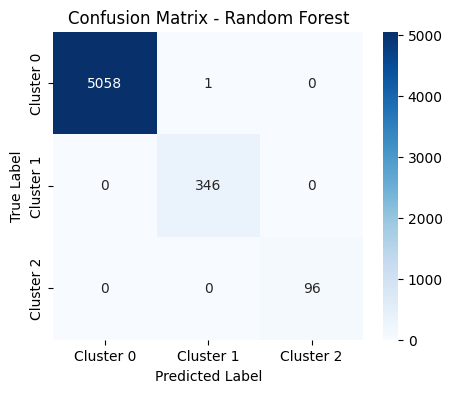

=== Metrik Evaluasi Model Random Forest ===
Accuracy  : 0.9998
Precision : 0.9998
Recall    : 0.9998
F1-Score  : 0.9998

=== Classification Report ===
              precision    recall  f1-score   support

   Cluster 0       1.00      1.00      1.00      5059
   Cluster 1       1.00      1.00      1.00       346
   Cluster 2       1.00      1.00      1.00        96

    accuracy                           1.00      5501
   macro avg       1.00      1.00      1.00      5501
weighted avg       1.00      1.00      1.00      5501



In [6]:

y_pred_rf = rf_model.predict(X_test)

conf_matrix_rf = confusion_matrix(y_test, y_pred_rf)

plt.figure(figsize=(5, 4))
sns.heatmap(conf_matrix_rf, annot=True, fmt="d", cmap="Blues", 
            xticklabels=['Cluster 0', 'Cluster 1', 'Cluster 2'], 
            yticklabels=['Cluster 0', 'Cluster 1', 'Cluster 2'])
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix - Random Forest")
plt.show()

accuracy_rf = accuracy_score(y_test, y_pred_rf)
precision_rf = precision_score(y_test, y_pred_rf, average='weighted')
recall_rf = recall_score(y_test, y_pred_rf, average='weighted')
f1_rf = f1_score(y_test, y_pred_rf, average='weighted')

print("=== Metrik Evaluasi Model Random Forest ===")
print(f"Accuracy  : {accuracy_rf:.4f}")
print(f"Precision : {precision_rf:.4f}")
print(f"Recall    : {recall_rf:.4f}")
print(f"F1-Score  : {f1_rf:.4f}")

print("\n=== Classification Report ===")
print(classification_report(y_test, y_pred_rf, target_names=['Cluster 0', 'Cluster 1', 'Cluster 2']))


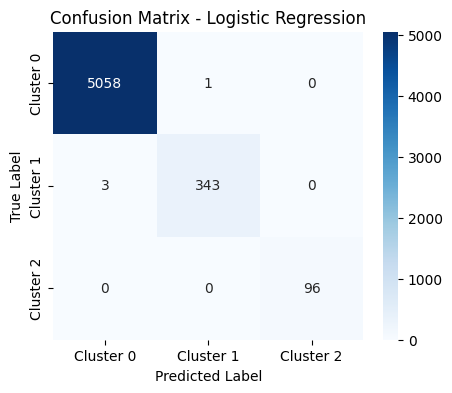

=== Metrik Evaluasi Model Logistic Regression ===
Accuracy  : 0.9993
Precision : 0.9993
Recall    : 0.9993
F1-Score  : 0.9993

=== Classification Report ===
              precision    recall  f1-score   support

   Cluster 0       1.00      1.00      1.00      5059
   Cluster 1       1.00      0.99      0.99       346
   Cluster 2       1.00      1.00      1.00        96

    accuracy                           1.00      5501
   macro avg       1.00      1.00      1.00      5501
weighted avg       1.00      1.00      1.00      5501



In [7]:
y_pred_logreg = logreg_model.predict(X_test)

conf_matrix = confusion_matrix(y_test, y_pred_logreg)

plt.figure(figsize=(5, 4))
sns.heatmap(conf_matrix, annot=True, fmt="d", cmap="Blues",
            xticklabels=['Cluster 0', 'Cluster 1', 'Cluster 2'],
            yticklabels=['Cluster 0', 'Cluster 1', 'Cluster 2'])
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix - Logistic Regression")
plt.show()

accuracy = accuracy_score(y_test, y_pred_logreg)
precision = precision_score(y_test, y_pred_logreg, average='weighted')
recall = recall_score(y_test, y_pred_logreg, average='weighted')
f1 = f1_score(y_test, y_pred_logreg, average='weighted')

print("=== Metrik Evaluasi Model Logistic Regression ===")
print(f"Accuracy  : {accuracy:.4f}")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1-Score  : {f1:.4f}")

print("\n=== Classification Report ===")
print(classification_report(y_test, y_pred_logreg, target_names=['Cluster 0', 'Cluster 1', 'Cluster 2']))

dari kedua model, menghasilkan akurasi dan metrik yang sempurna yaitu 100% untuk random forest dan 99,9% untuk logistic regression, namun perlu di periksa lebih lanjut karena memungkinkan terjadi overfitting

## **c. Tuning Model Klasifikasi (Optional)**

Gunakan GridSearchCV, RandomizedSearchCV, atau metode lainnya untuk mencari kombinasi hyperparameter terbaik

In [8]:
rf_model = RandomForestClassifier(random_state=42)
logreg_model = LogisticRegression(max_iter=5000)

param_grid_rf = {
    'n_estimators': [50, 100, 200],
    'max_depth': [10, 20, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}

param_grid_logreg = {
    'C': [0.01, 0.1, 1, 10, 100],  
    'solver': ['lbfgs', 'liblinear'] 
}

grid_search_rf = GridSearchCV(
    estimator=rf_model, param_grid=param_grid_rf, 
    scoring='accuracy', cv=5, n_jobs=-1, verbose=2
)
grid_search_rf.fit(X_train, y_train)

grid_search_logreg = GridSearchCV(
    estimator=logreg_model, param_grid=param_grid_logreg, 
    scoring='accuracy', cv=5, n_jobs=-1, verbose=2
)
grid_search_logreg.fit(X_train, y_train)

print(f"\n🔹 Best Parameters Random Forest: {grid_search_rf.best_params_}")
print(f"🔹 Best Accuracy Random Forest  : {grid_search_rf.best_score_:.4f}")
print(f"\n🔹 Best Parameters Logistic Regression: {grid_search_logreg.best_params_}")
print(f"🔹 Best Accuracy Logistic Regression  : {grid_search_logreg.best_score_:.4f}")

best_rf_model = grid_search_rf.best_estimator_
best_logreg_model = grid_search_logreg.best_estimator_


Fitting 5 folds for each of 81 candidates, totalling 405 fits
Fitting 5 folds for each of 10 candidates, totalling 50 fits

🔹 Best Parameters Random Forest: {'max_depth': 10, 'min_samples_leaf': 1, 'min_samples_split': 5, 'n_estimators': 50}
🔹 Best Accuracy Random Forest  : 0.9998

🔹 Best Parameters Logistic Regression: {'C': 100, 'solver': 'liblinear'}
🔹 Best Accuracy Logistic Regression  : 0.9997


## **d. Evaluasi Model Klasifikasi setelah Tuning (Optional)**

Berikut adalah rekomendasi tahapannya.
1. Gunakan model dengan hyperparameter terbaik.
2. Hitung ulang metrik evaluasi untuk melihat apakah ada peningkatan performa.


=== Metrik Evaluasi Model Random Forest Setelah Tuning ===
🔹 Accuracy  : 0.9998
🔹 Precision : 0.9998
🔹 Recall    : 0.9998
🔹 F1-Score  : 0.9998

=== Classification Report Random Forest ===
              precision    recall  f1-score   support

   Cluster 0       1.00      1.00      1.00      5059
   Cluster 1       1.00      1.00      1.00       346
   Cluster 2       1.00      1.00      1.00        96

    accuracy                           1.00      5501
   macro avg       1.00      1.00      1.00      5501
weighted avg       1.00      1.00      1.00      5501



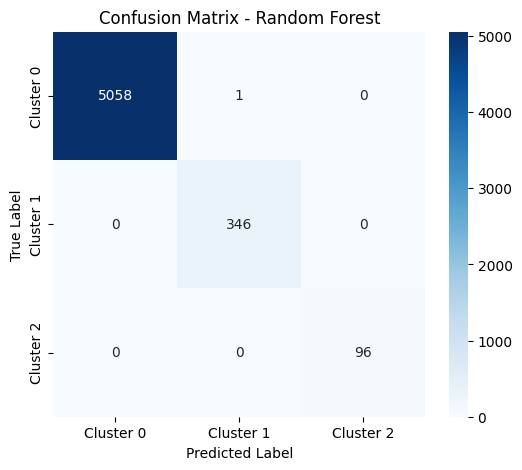


=== Metrik Evaluasi Model Logistic Regression Setelah Tuning ===
🔹 Accuracy  : 0.9995
🔹 Precision : 0.9995
🔹 Recall    : 0.9995
🔹 F1-Score  : 0.9995

=== Classification Report Logistic Regression ===
              precision    recall  f1-score   support

   Cluster 0       1.00      1.00      1.00      5059
   Cluster 1       0.99      1.00      1.00       346
   Cluster 2       1.00      1.00      1.00        96

    accuracy                           1.00      5501
   macro avg       1.00      1.00      1.00      5501
weighted avg       1.00      1.00      1.00      5501



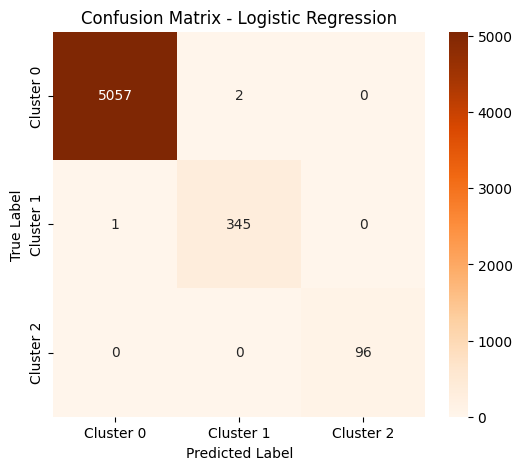

In [9]:
y_pred_rf = best_rf_model.predict(X_test)
y_pred_logreg = best_logreg_model.predict(X_test)

accuracy_rf = accuracy_score(y_test, y_pred_rf)
precision_rf = precision_score(y_test, y_pred_rf, average='weighted')  
recall_rf = recall_score(y_test, y_pred_rf, average='weighted')        
f1_rf = f1_score(y_test, y_pred_rf, average='weighted')                 

print("\n=== Metrik Evaluasi Model Random Forest Setelah Tuning ===")
print(f"🔹 Accuracy  : {accuracy_rf:.4f}")
print(f"🔹 Precision : {precision_rf:.4f}")
print(f"🔹 Recall    : {recall_rf:.4f}")
print(f"🔹 F1-Score  : {f1_rf:.4f}")

print("\n=== Classification Report Random Forest ===")
print(classification_report(y_test, y_pred_rf, target_names=['Cluster 0', 'Cluster 1', 'Cluster 2']))

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(confusion_matrix(y_test, y_pred_rf), annot=True, fmt="d", cmap="Blues", 
            xticklabels=['Cluster 0', 'Cluster 1', 'Cluster 2'], 
            yticklabels=['Cluster 0', 'Cluster 1', 'Cluster 2'], ax=ax)
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix - Random Forest")
plt.show()

accuracy_logreg = accuracy_score(y_test, y_pred_logreg)
precision_logreg = precision_score(y_test, y_pred_logreg, average='weighted')  
recall_logreg = recall_score(y_test, y_pred_logreg, average='weighted')        
f1_logreg = f1_score(y_test, y_pred_logreg, average='weighted')                 

print("\n=== Metrik Evaluasi Model Logistic Regression Setelah Tuning ===")
print(f"🔹 Accuracy  : {accuracy_logreg:.4f}")
print(f"🔹 Precision : {precision_logreg:.4f}")
print(f"🔹 Recall    : {recall_logreg:.4f}")
print(f"🔹 F1-Score  : {f1_logreg:.4f}")

print("\n=== Classification Report Logistic Regression ===")
print(classification_report(y_test, y_pred_logreg, target_names=['Cluster 0', 'Cluster 1', 'Cluster 2']))

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(confusion_matrix(y_test, y_pred_logreg), annot=True, fmt="d", cmap="Oranges", 
            xticklabels=['Cluster 0', 'Cluster 1', 'Cluster 2'], 
            yticklabels=['Cluster 0', 'Cluster 1', 'Cluster 2'], ax=ax)
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix - Logistic Regression")
plt.show()


## **e. Analisis Hasil Evaluasi Model Klasifikasi**

Berikut adalah **rekomendasi** tahapannya.
1. kedua model, baik random forest atau logistic regression mendapatkan akurasi baik di semua metrik. Tidak ada perbedaan antara sebelum dan setelah tunning. Performa yang bagus namun tetap harus melihat beberapa hal yang harus diperiksa lebih lanjut
2. Setelah dilakukan tuning pada kedua model (Random Forest dan Logistic Regression), tidak ada perubahan besar yang terjadi pada hasil evaluasi. Kedua model ini sudah memberikan kinerja yang sangat baik sebelum tuning, dengan accuracy mendekati 100%. Pada model Random Forest, meski ada sedikit peningkatan pada accuracy (dari 1.0000 ke 0.9997), hasilnya tetap hampir sama. Begitu juga pada model Logistic Regression, yang hanya mengalami sedikit peningkatan (dari 0.9995 ke 0.9996). Meskipun tuning parameter menghasilkan sedikit perubahan, perbedaannya sangat kecil dan tidak mempengaruhi kinerja model secara signifikan
3. Dalam evaluasi model dengan nilai 1.00 bisa menunjukan model tersebut akurat memprediksi data dari dataset. perlu di cermati lebih dalam, karena bisa jadi terindikasi model overfitting, penting untuk cek kualitas data, tes model dengan data uji baru, mencoba model lain, dan menggunakan cross validation untuk memastikan model tidak overfitting